## Lernziel

Aus Szenarioparametern einen schematischen Schnitt erzeugen, Darstellungsstile vergleichen und fachliche Overlays erkunden.

**Voraussetzungen:** Gespeicherte PEExcel-Exporte; keine Excel-Installation erforderlich.

Einmalig im Repository installieren: `python -m pip install -e ".[publication]"`.
Zum eigenen Ausführen das Notebook im geklonten Repository öffnen und die Zellen von oben nach unten ausführen.
Die Website zeigt gespeicherte Ausgaben; sie führt keinen Python-Code im Browser aus.

[Tutorial-Notebook herunterladen](downloads/tutorial_gebaeudeschnitt.ipynb) · [Alle Tutorials](python.qmd)


## 1. Szenario und Darstellungsannahmen

Das Beispiel verwendet die versionierte Entwicklungsdatei. Der Renderer zeichnet eine schematische Anordnung;
er ersetzt keinen Gebäudeplan. Grundriss, Abstände und Bauteilpositionen sind Darstellungsannahmen.

Variante: Beispiel | Alle Energiesysteme


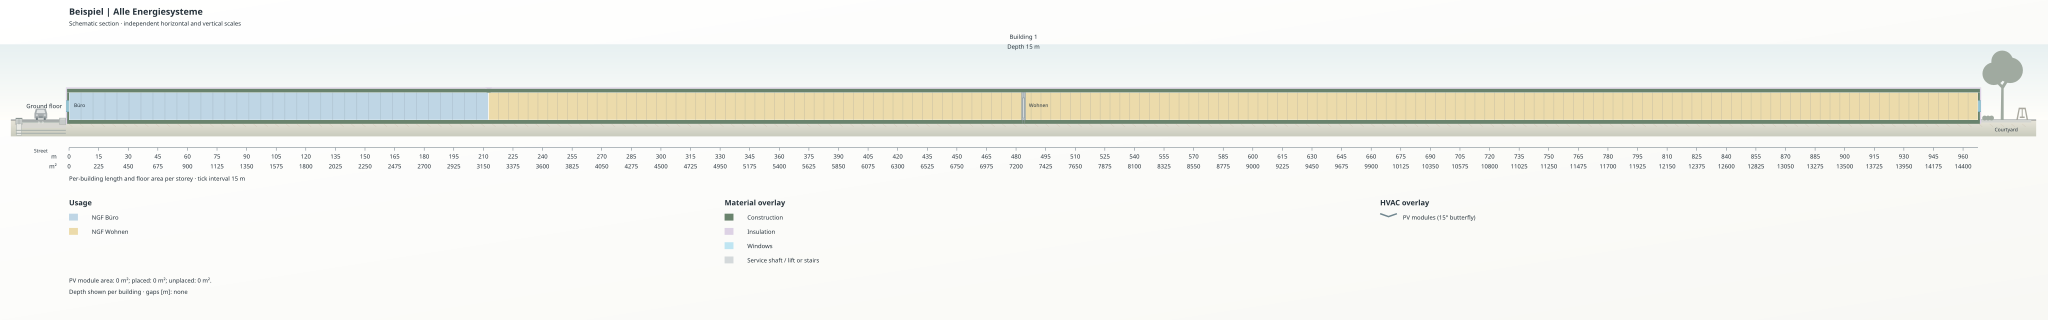

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display

# Im geklonten Repository ausführen, z. B. aus website/ oder notebooks/.
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "src/pexl").is_dir() and (p / "pyproject.toml").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Bitte das Notebook innerhalb des peexcel-Repositorys öffnen.")
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "scripts"))
OUTPUT = ROOT / "notebooks/local_exports/tutorials"
OUTPUT.mkdir(parents=True, exist_ok=True)
from pexl import Project
from pexl.spatial import section_layout_from_scenario, render_svg
from IPython.display import SVG
projekt = Project.example()
szenario = projekt.scenarios[0]
schnitt = section_layout_from_scenario(szenario, seed=42)
print("Variante:", szenario.column_name)
display(SVG(render_svg(schnitt)))

## 2. Stil ändern, Geometrie erhalten

Der Lehrstil reduziert Dekoration. Derselbe Schnitt bleibt die Eingabe;
die Änderung betrifft die Darstellung, nicht die Energiekennzahlen.

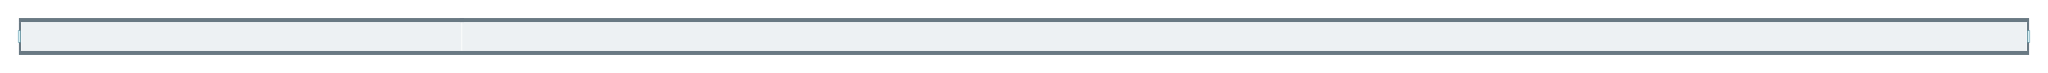

,code,description
0,default_building_count,Missing building_count: assumed 1.
1,default_storey_count_avg,Missing storey_count_avg: assumed 1.
2,schematic_depth,A common section depth of 15 m is assumed.
3,schematic_geometry,"NFA-based widths, uniform room heights, flat r..."
4,default_distribution,"After ground-floor retail, each school and off..."
5,balanced_tops,"After filling buffer gaps, remaining residenti..."
6,adapted_buildings,Building count and usage areas are preserved; ...
7,building_gaps,Gaps between schematic floor footprints [m]: [...
8,roof_pv,PV area placement uses flat schematic roof cap...


In [2]:
display(SVG(render_svg(schnitt, style="teaching")))
display(pd.DataFrame(schnitt["assumptions"]))

## 3. SVG weiterverwenden

SVG speichert die Zeichnung als Vektorgrafik. Für reproduzierbare Vergleiche Szenario, Parameter und Annahmen mit dokumentieren.

In [3]:
datei = OUTPUT / "tutorial_gebaeudeschnitt.svg"
datei.write_text(render_svg(schnitt, style="teaching"), encoding="utf-8")
print("SVG gespeichert:", datei.name)

SVG gespeichert: tutorial_gebaeudeschnitt.svg


## 4. Interaktive Lehransicht

Das vorhandene Lehrmodul verwendet dieselben räumlichen Funktionen. Es zeigt ausdrücklich vorbereitete
Lehrbeispiele, nicht automatisch die oben gewählte Variante. Es wird als abgeschlossene HTML-Anwendung eingebettet.
Probiere Hülle, Kellerzone und einzelne Wärmeflüsse aus.

In [4]:
from section_teaching_preview import build_preview
from IPython.display import HTML
from html import escape
lehrdatei = build_preview(OUTPUT / "lehrschnitt")
display(HTML('<iframe title="Interaktiver Lehrschnitt" style="width:100%;height:850px;border:0" srcdoc="'
             + escape(lehrdatei.read_text(encoding="utf-8"), quote=True) + '"></iframe>'))

C:\Users\schneids\AppData\Roaming\Python\Python313\site-packages\IPython\core\display.py:447: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


## Ergebnis und Grenzen

Schnitt und Overlays helfen beim Erklären von Geometrie und Bilanzgrenzen. Pfeile sind qualitative
Lehrdarstellungen; sie sind kein Nachweis einer simulierten Leistung. Für detaillierte Gebäudeanordnung,
Anlagensymbole und Dachnutzungen enthält das ursprüngliche `howto_visualize_project` weitere Beispiele.



## Weiterarbeiten

[Zur Tutorial-Übersicht](python.qmd). Die ursprünglichen Arbeitsnotebooks bleiben erhalten: [howto_visualize_project](https://github.com/simonschaluppe/peexcel/blob/master/notebooks/howto_visualize_project.ipynb), [howto_section_teaching_preview](https://github.com/simonschaluppe/peexcel/blob/master/notebooks/howto_section_teaching_preview.ipynb).


## Older exports: inspect, complete, retry

The current schema defines `scenario.v`. With `unknown="ignore"`, export names outside that schema remain in `scenario.legacy` for manual inspection only. They are not selected, calculated or written by the current-schema exporter. Version labels alone do not establish compatibility. Renamed fields in Python functions must still be maintained when the current schema changes.

Missing optional PV sizing omits PV geometry; `assumptions` explains the limitation. Missing required floor area raises `ValueError`. Inspect units and physical meaning before copying a legacy value. For example, assign `scenario.v.PV_module_area = 40.0` (m²) only when justified. This changes the in-memory scenario, not the source workbook. `scenario.v.PV_roof_share = scenario.legacy["PV_roof_area_percentage"]` is appropriate only after checking equal units and meaning; no automatic migration occurs.


In [ ]:
from pathlib import Path
from copy import deepcopy
from pexl import Project
from pexl.spatial import section_layout_from_scenario

repo = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/pexl").is_dir())
older = Project.from_excel(repo / "data/exports/examples/ka_examples_v1.09.xlsx", unknown="ignore")
print(*older.warnings, sep="\n")
successes, skipped = [], []
for candidate in older:
    try:
        result = section_layout_from_scenario(candidate)
    except ValueError as error:
        skipped.append((candidate.column_name, str(error)))
    else:
        successes.append(candidate)
print(f"{len(successes)} successful; {len(skipped)} skipped")
for name, reason in skipped:
    print(name, reason)
print("For missing floor area: supply candidate.v.NFA_total in m², consistent with known usage areas, then retry.")

example = deepcopy(successes[0])
print("Legacy fields:", list(example.legacy))
# Demonstrate missing optional sizing without altering the loaded project.
example.v.PV_is_used = 1
example.v.PV_module_area = example.v.PV_kWp = example.v.PV_m2_per_kWp = None
print(section_layout_from_scenario(example)["assumptions"])
# Illustrative expert input, not an inferred value for the original project:
example.v.PV_module_area = 40.0
completed = section_layout_from_scenario(example)
assert not any(n["code"] == "unknown_pv_area" for n in completed["assumptions"])
